# Topic modelling and visualisation

This notebook makes use of cleaned corpus files saved from question 3.

In [15]:
# load libraries
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pyLDAvis
import pyLDAvis.lda_model

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation


In [16]:
# load data
path = Path("../data/processed/cleaned_research_corpus.csv")

corpus = pd.read_csv(path)

In [17]:
# view data
corpus.head()

,article_id,content,word_count,character_count,cleaned_content
0,research_1,The purposes of this article are to position m...,5602,38160,The purposes of this article are to position m...
1,research_2,"Now I see it, now I don’t:\nresearcher’s posit...",2416,16104,"Now I see it, now I don’t: researcher’s positi..."
2,research_3,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,3828,26154,DEVELOPMENTAL RESEARCH: STUDIES OF INSTRUCTION...
3,research_4,Abstract\nCronbach’s alpha is a statistic comm...,5922,38950,Abstract Cronbach’s alpha is a statistic commo...
4,research_5,Denzin’s Paradigm Shift: Revisiting Triangulat...,4027,26831,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [18]:
# inspect cleaned corpus
print('Documents:', len(corpus))
print('First cleaned article excerpt:', corpus.loc[0, 'cleaned_content'][:400])

Documents: 5
First cleaned article excerpt: The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In doing this, we briefly review the paradig


Topic 1: development, developmental, design, instructional, evaluation, type, models, product, specific, learning, orientation, technology
Topic 2: alpha, cronbach, instrument, science, reliability, items, researcher, education, reflexivity, internal, scales, statistic
Topic 3: methods, mixed, researchers, quantitative, purists, paradigm, reality, paradigms, educational, important, guba, specific
Topic 4: triangulation, methods, denzin, fusch, design, multiple, researchers, researcher, mixed, change, validity, method
article_id  Topic 1  Topic 2  Topic 3  Topic 4
research_1      0.0    0.000      1.0      0.0
research_2      0.0    0.999      0.0      0.0
research_3      1.0    0.000      0.0      0.0
research_4      0.0    1.000      0.0      0.0
research_5      0.0    0.000      0.0      1.0


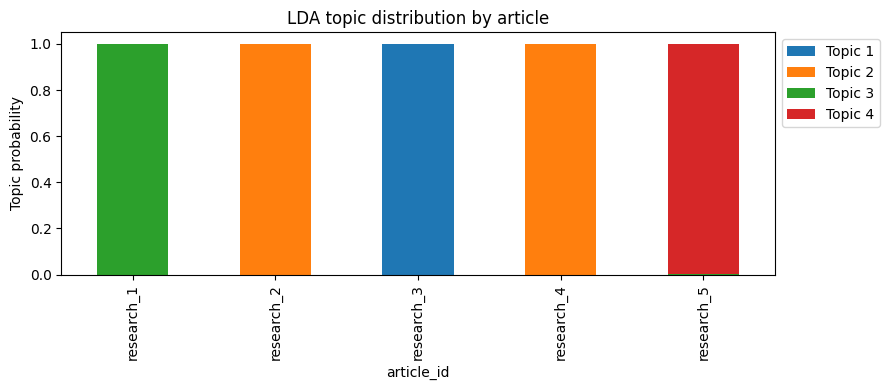

In [19]:
# extract features
SEED=42

custom_stopwords = list(ENGLISH_STOP_WORDS | {'research', 'study', 'article', 'paper', 'authors', 'author'})
count_vectorizer = CountVectorizer(stop_words=custom_stopwords,
                                   token_pattern=r'(?u)\b[a-zA-Z]{3,}\b',
                                   max_df=0.95, min_df=1)
counts = count_vectorizer.fit_transform(corpus['cleaned_content'])

# fit model
n_topics = 4
lda = LatentDirichletAllocation(n_components=n_topics, random_state=SEED,
                                learning_method='batch', max_iter=30)
topic_probabilities = lda.fit_transform(counts)
terms = count_vectorizer.get_feature_names_out()
for i, weights in enumerate(lda.components_, start=1):
    top = terms[np.argsort(weights)[-12:][::-1]]
    print(f'Topic {i}:', ', '.join(top))
distribution = pd.DataFrame(topic_probabilities,
                            columns=[f'Topic {i}' for i in range(1, n_topics + 1)])
distribution.insert(0, 'article_id', corpus['article_id'])
print(distribution.round(3).to_string(index=False))
distribution.to_csv("../data/processed/lda_topic_distribution.csv", index=False)

# visualise results
fig, ax = plt.subplots(figsize=(9, 4))
distribution.set_index('article_id').plot(kind='bar', stacked=True, ax=ax)
ax.set_ylabel('Topic probability')
ax.set_title('LDA topic distribution by article')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [20]:
# visualise topics
visualisation = pyLDAvis.lda_model.prepare(
    lda,
    counts,
    count_vectorizer
)

pyLDAvis.display(visualisation)

In [21]:
# save visualisation
pyLDAvis.save_html(
    visualisation,
    "../docs/lda_visualisation.html"
)